# Catalogs by design: interloper fractions

This notebook builds catalogs whose interlopers are chosen in advance: the share of the catalog each kind of interloper
makes. It follows the two steps of notebooks 01 and 02 with two new pieces.

1. **`base.make_proposal(z_range, line, flux_limit, interloper_fraction=...)`** takes the total interloper fraction
   expected in the catalog. Besides the single-line fractions and the potential interlopers, the proposal scans the
   **secondary limit**, the threshold above which a galaxy's other lines are detected. A higher secondary limit leaves
   more galaxies with a single line, and so more potential interlopers. For every secondary limit, the proposal gives
   how much of the catalog each kind of interloper can make (if every one were taken), the total, and from which
   secondary limit the expected total is possible. The scan costs nothing extra: every sensitivity model puts the
   secondary limit at a fixed fraction of the primary one, so one number per galaxy decides its lines at every
   secondary limit.
2. **`proposal.make_catalog(fractions=..., secondary_flux_limit=..., out_dir=...)`** takes the table of interloper
   fractions, e.g. `{"Ha": {"OIII_5007": 0.005, "SIII_9532": 0.005}}`. The [O III] λ5007 and [S III] λ9532 galaxies
   taken for Hα each make 0.5 % of the catalog (of the Hα sample for `line="Ha"`; of every galaxy for `line="all"`).
   With `N` the sample, `n` the potential interlopers of a pair at the chosen secondary limit and `F` the sum of the
   fractions, the catalog holds `N / (1 − F)` galaxies. A single line of the pair, where it would get a redshift inside
   the range, is taken for Hα with the probability `P = f N / ((1 − F) n)`. Every other galaxy keeps its line, so no
   galaxy of the sample is lost.

The proposal here gives no secondary limit. With an expected interloper fraction, its own tables are then those of a
single tier (the secondary limit at the primary one), and step 2 chooses the secondary limit. Without
`interloper_fraction` it would be a proposal for single-line clean catalogs (notebook 05).

Run it on a CPU node, from the package directory: `sbatch scripts/run_notebook.sh notebooks/04_catalog_by_design.ipynb`
(about 4 minutes). The catalogs go to `$PSCRATCH/RomanMocks/examples/`.

In [1]:
import os
os.environ.setdefault("JAX_PLATFORMS", "cpu")      # romanmock imports diffsky, which imports JAX; keep it off the GPU

import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from romanmock import BaseCatalog, Catalog, Proposal, plotting
from romanmock.plotting import OUTCOME_COLORS, TEXT_PRIMARY, feature_color, feature_label

plotting.use_style()
BASE = "/global/cfs/cdirs/m4943/Simulations/RomanMocks/sdss_feniks_hizels_261013_10_14_2026/base"
OUT = Path(os.environ["PSCRATCH"]) / "RomanMocks" / "examples"      # scratch: purged after 8 weeks without access
N_WORKERS = 64 if "SLURM_JOB_ID" in os.environ else None           # a whole CPU node; None: what a login node allows
base = BaseCatalog(BASE)
print(base)


<BaseCatalog /global/cfs/cdirs/m4943/Simulations/RomanMocks/sdss_feniks_hizels_261013_10_14_2026/base: 403,068,868 galaxies in 67 slices, 0.00 < z < 4.00; flux limit 1.00e-18 erg/s/cm2 in 10000-19300 A; lines ['Ha', 'Hb', 'OIII_5007', 'OIII_4959', 'OII_3727', 'SIII_9532', 'SIII_9069', 'OIII_4363', 'SIII_6312', 'PaA']>


## Step 1: the proposal and the scan of the secondary limit

The inputs are Hα at 1.0 < z < 1.2, a primary flux limit of 1.5 × 10⁻¹⁶ erg s⁻¹ cm⁻², and 1 % of interlopers expected in
all. The summary ends with **Interlopers against the secondary limit**. Its rows are the kinds of interloper and the
total; its columns are secondary limits, from where any interloper becomes possible up to the primary limit.
Each value is the share of the catalog if every potential interloper were taken, the most
any identification gives. `proposal.plot_secondary()` draws it: the dashed line is the expected total, and the dot the
lowest secondary limit that allows it.

[romanmock] line = "Ha": which galaxies the catalog holds
  ▶ "Ha"         the galaxies in which Hα is identified, with z = λ_obs / 6564.7 Å − 1 inside
                 z_range: Hα detected, alone or with other lines, or a single line taken for Hα (an
                 interloper)
    "OIII_5007"  the same for [O III] λ5007, z = λ_obs / 5008.3 Å − 1; a galaxy with both lines is
                 in both catalogs
    "all"        every galaxy with a redshift inside z_range, whichever line gave it
    or           "Hb", "OIII_4959", "OII_3727", "SIII_9532", "SIII_9069", "OIII_4363", "SIII_6312",
                 "PaA"


[romanmock] proposal: scanning 32 of 67 slices with 64 worker(s) …

 done in 31 s



━━ Proposal · Hα at 1.0 ≤ z ≤ 1.2 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  thresholds    F > 1.50e-16
  line fluxes   rescaled (galacticus_like)
  doublet       OIII_4959 a line of its own where the doublet is resolved for the galaxy's size
                (dip ≥ 20 %), added to OIII_5007 where blended; merged in 57 % of the detected
                galaxies with both lines in the bandpass
  sample        12,617,496 galaxies with Hα detected at 1.0 ≤ z < 1.2 (4,894 per deg²)
  interlopers   1.00 % of the catalog expected in all

── Single-line galaxies inside the range ───────────────────────────────────────────────────────────
  line        galaxies   share¹
  ─────────  ─────────  ───────
  all        5,395,334  35.99 %
  Ha         3,022,332  20.16 %
  OIII_5007  2,373,002  15.83 %
  ¹ of the 14,991,531 galaxies detected at 1.0 ≤ z < 1.2 (true redshift)

── Potential interlopers ───────────────────────────────────────────────────────────────────────────


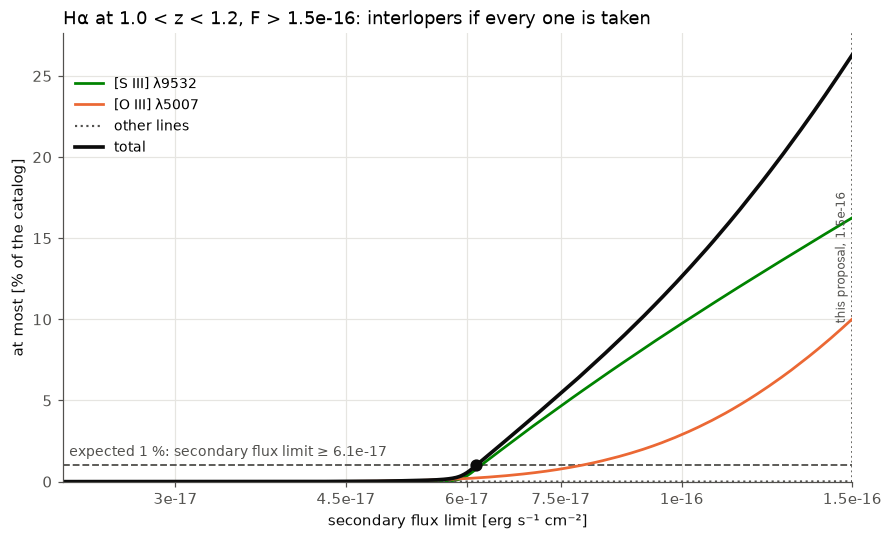

In [2]:
proposal = base.make_proposal((1.0, 1.2), line="Ha", flux_limit=1.5e-16, interloper_fraction=0.01, n_workers=N_WORKERS)
proposal.plot_secondary()
plt.show()


With a single tier the sample is the 12.62 M galaxies with Hα above the primary limit (4,894 per deg²). The scan
shows where the interlopers can come from:

* **Below a secondary flux limit of 5.8 × 10⁻¹⁷ no [S III] λ9532 galaxy is single-line.** The mock's λ9532/λ9069 ratio
  is fixed (2.57 after the rescaling), so λ9069 stays above any lower secondary limit. Almost no [O III] galaxy is
  single-line below it either, and none at all below 2.3 × 10⁻¹⁷.
* **Between 6 and 8 × 10⁻¹⁷ the possible interlopers jump from 0.55 % to 6.9 % of the catalog**, mostly [S III]. At the
  primary limit they could be 26 % of it.
* **The expected 1 % needs a secondary flux limit of at least 6.1 × 10⁻¹⁷**: the dot in the figure.

## Step 2: the design and the catalog

The table is 0.5 % of [O III] λ5007 interlopers and 0.5 % of [S III] λ9532 ones, at a secondary flux limit of
7.5 × 10⁻¹⁷ (half the primary limit). `proposal.design` says what the table takes without making the catalog: the
potential interlopers of each pair, and the probability P that such a single line is taken for Hα.

In [3]:
table = {"Ha": {"OIII_5007": 0.005, "SIII_9532": 0.005}}
d = proposal.design(table, secondary_flux_limit=7.5e-17)
for r in d["pairs"]:
    print(f"{r['line']:>10s} as {r['as']}: {100 * r['fraction']:.2f} % of the catalog, {r['n_potential']:,.0f} potential, "
          f"P = {r['p']:.4f}, {r['n_expected']:,.0f} expected")
print(f"catalog: {d['n_sample']:,.0f} galaxies in the sample -> {d['n_catalog']:,.0f} with the interlopers")


 OIII_5007 as Ha: 0.50 % of the catalog, 122,663 potential, P = 0.6120, 75,065 expected
 SIII_9532 as Ha: 0.50 % of the catalog, 732,760 potential, P = 0.1024, 75,065 expected
catalog: 14,862,918 galaxies in the sample -> 15,013,049 with the interlopers


A table that needs more interlopers than there are single lines is refused, with the lowest secondary limit that
meets it:

In [4]:
try:
    proposal.design({"Ha": {"OIII_5007": 0.02}}, secondary_flux_limit=7.5e-17)
except ValueError as err:
    print("ValueError:", err)


ValueError: too few single lines at a secondary flux limit of 7.5e-17: OIII_5007 -> Ha 2 % needs 303,325 of the 122,663 there are; the table can be met with a secondary flux limit of at least 9e-17, or ask for smaller fractions


`make_catalog(fractions=...)` prints the design, makes the catalog, and prints its summary, its line report and the
fractions asked and made. The summary file keeps the design and the fractions made.

In [5]:
cat = proposal.make_catalog(fractions=table, secondary_flux_limit=7.5e-17, out_dir=OUT / "Ha_z1p0_1p2_design",
                            n_workers=N_WORKERS)


━━ Interlopers by design · Hα at 1.0 ≤ z ≤ 1.2 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  thresholds   F > 1.50e-16 (other lines > 7.50e-17)
  sample       14,862,918 galaxies with Hα detected inside the range
  catalog      15,013,049 galaxies expected, 1.00 % of them interlopers

  line       fraction¹  potential²      P³  expected
  ─────────  ─────────  ──────────  ──────  ────────
  OIII_5007    0.500 %     122,663  0.6120    75,065
  SIII_9532    0.500 %     732,760  0.1024    75,065
  ¹ asked: the share of the catalog
  ² single lines where Hα would be inside the range, at a secondary flux limit of 7.5e-17
  ³ the probability that such a single line is taken for Hα; elsewhere, and for the lines not
    listed, the identification is correct



[romanmock] catalog: scanning 67 slices with 64 worker(s) …

 done in 29 s



━━ Catalog · Hα · 1.0 ≤ z_assigned ≤ 1.2 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  thresholds       F > 1.50e-16 (other lines > 7.50e-17)
  line fluxes      rescaled (galacticus_like); [O III] doublet per_galaxy
  identification   by design, shares of the catalog: OIII_5007 → Ha 0.5 % (P 0.612), SIII_9532 → Ha
                   0.5 % (P 0.102)
  sky area         2578.31 deg² (estimated from the sky patches of the mock)
  base catalog     100,805,121 of its 403,068,868 galaxies detected
  columns          gal_id, ra, dec, redshift_true, redshift_rsd, redshift_assigned, id_outcome,
                   line_true, line_assigned, n_det

  galaxies                                       number     share
  ─────────────────────────────────────────  ──────────  ────────
  multi-line                                 14,541,036   96.86 %
  single line, correct redshift                 321,887    2.14 %
  single line taken for another: interloper     150,051    1.00 %
  all    


── Interlopers by design: asked and made ───────────────────────────────────────────────────────────
  line         asked     made  interlopers  expected
  ─────────  ───────  ───────  ───────────  ────────
  OIII_5007  0.500 %  0.499 %       74,973    75,065
  SIII_9532  0.500 %  0.500 %       75,078    75,065
  15,012,974 galaxies in the catalog (15,013,049 expected); each pair's interlopers are drawn one by
  one, so their number scatters by about its square root



[romanmock] wrote to /pscratch/sd/w/willlake/RomanMocks/examples/Ha_z1p0_1p2_design/
            Ha_z1p0_1p2.hdf5, Ha_z1p0_1p2_summary.json, Ha_z1p0_1p2_proposal.npz


At 7.5 × 10⁻¹⁷ there are 122,663 potential [O III] interlopers and 732,760 [S III] λ9532 ones:

* **The design** takes [O III] for Hα with P = 0.612 and [S III] with P = 0.102, about 75,065 of each. The catalog
  grows from the 14.86 M galaxies of the sample to 15.01 M.
* **Made:** 0.499 % [O III] (74,973) and 0.500 % [S III] (75,078), within the binomial scatter of about ±270.
* **Nothing else changes.** The 14,862,923 galaxies with a correct redshift are the sample. The design's 14,862,918 comes
  from the scan, interpolated between its edges.
* **2 % of [O III] would need 303,325** of the 122,663 single lines there are. It is refused, and the lowest secondary
  limit that meets it is 9 × 10⁻¹⁷.

In proportion to their numbers, 1 % is 0.86 % [S III] and 0.14 % [O III] at 7.5 × 10⁻¹⁷, and 0.77 % and 0.23 % at
10⁻¹⁶, where [O III] catches up.

## A total shared in proportion

`proposal.fraction_template(total, secondary_flux_limit=...)` shares an expected total among the potential interlopers in
proportion to their numbers at that secondary limit, so every one of them is taken with the same probability. The table
can be edited before `make_catalog`.

In [6]:
for second in (7.5e-17, 1e-16):
    print(f"secondary {second:.2g}:", proposal.fraction_template(0.01, secondary_flux_limit=second))


secondary 7.5e-17: {'Ha': {'SIII_9532': 0.008566, 'OIII_5007': 0.001434}}
secondary 1e-16: {'Ha': {'SIII_9532': 0.007708, 'OIII_5007': 0.002292}}


## S/N thresholds

The same scan with S/N ≥ 5 for the primary line, for the size of each galaxy, with 3 % of interlopers expected. The
columns are then secondary S/N values, and `make_catalog(fractions=..., secondary_snr=..., ...)` would make the
catalog.

[romanmock] line = "Ha": which galaxies the catalog holds
  ▶ "Ha"         the galaxies in which Hα is identified, with z = λ_obs / 6564.7 Å − 1 inside
                 z_range: Hα detected, alone or with other lines, or a single line taken for Hα (an
                 interloper)
    "OIII_5007"  the same for [O III] λ5007, z = λ_obs / 5008.3 Å − 1; a galaxy with both lines is
                 in both catalogs
    "all"        every galaxy with a redshift inside z_range, whichever line gave it
    or           "Hb", "OIII_4959", "OII_3727", "SIII_9532", "SIII_9069", "OIII_4363", "SIII_6312",
                 "PaA"


[romanmock] proposal: scanning 32 of 67 slices with 64 worker(s) …

 done in 45 s



━━ Proposal · Hα at 1.0 ≤ z ≤ 1.2 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  thresholds    S/N ≥ 5, size r50_disk_2d [kpc] / D_A(redshift_true), 1 h, 2 x min zodi
  line fluxes   rescaled (galacticus_like)
  doublet       OIII_4959 a line of its own where the doublet is resolved for the galaxy's size
                (dip ≥ 20 %), added to OIII_5007 where blended; merged in 31 % of the detected
                galaxies with both lines in the bandpass
  sample        16,449,077 galaxies with Hα detected at 1.0 ≤ z < 1.2 (6,380 per deg²)
  interlopers   3.00 % of the catalog expected in all

── Single-line galaxies inside the range ───────────────────────────────────────────────────────────
  line        galaxies   share¹
  ─────────  ─────────  ───────
  all        9,851,428  59.14 %
  Ha         9,642,319  57.88 %
  OIII_5007    209,109   1.26 %
  ¹ of the 16,658,187 galaxies detected at 1.0 ≤ z < 1.2 (true redshift)

── Potential interlopers ─────────────────

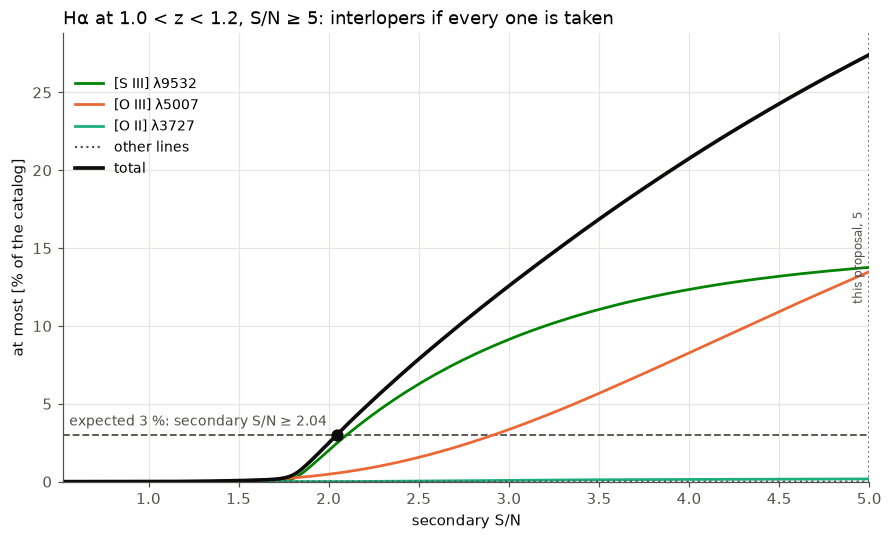

In [7]:
proposal_snr = base.make_proposal((1.0, 1.2), line="Ha", snr=5, size="r50_disk_2d", interloper_fraction=0.03,
                                  n_workers=N_WORKERS)
proposal_snr.plot_secondary()
plt.show()


With S/N ≥ 5 and a single tier, the sample is 16.45 M galaxies (6,380 per deg²):

* [O III] can be single-line from a secondary S/N of about 1.5 and [S III] λ9532 from 2;
* at most 2.5 % of the catalog at secondary S/N 2, 7.9 % at 2.5 and 27 % at 5, the primary S/N;
* the expected 3 % needs a secondary S/N of at least 2.04.

## Every galaxy at 1.6 < z < 2.0

For `line="all"` a potential interloper is a pair, a line taken for another, and the fractions are shares of the whole
catalog. Here the expected 3 % is shared in proportion at a secondary limit of 7.5 × 10⁻¹⁷.

[romanmock] line = "all": which galaxies the catalog holds
    "Ha"         the galaxies in which Hα is identified, with z = λ_obs / 6564.7 Å − 1 inside
                 z_range: Hα detected, alone or with other lines, or a single line taken for Hα (an
                 interloper)
    "OIII_5007"  the same for [O III] λ5007, z = λ_obs / 5008.3 Å − 1; a galaxy with both lines is
                 in both catalogs
  ▶ "all"        every galaxy with a redshift inside z_range, whichever line gave it
    or           "Hb", "OIII_4959", "OII_3727", "SIII_9532", "SIII_9069", "OIII_4363", "SIII_6312",
                 "PaA"


[romanmock] proposal: scanning 67 of 67 slices with 64 worker(s) …

 done in 38 s



━━ Proposal · every galaxy at 1.6 ≤ z ≤ 2.0 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  thresholds    F > 1.50e-16
  line fluxes   rescaled (galacticus_like)
  doublet       OIII_4959 a line of its own where the doublet is resolved for the galaxy's size
                (dip ≥ 20 %), added to OIII_5007 where blended; merged in 57 % of the detected
                galaxies with both lines in the bandpass
  sample        11,446,804 detected galaxies at 1.6 ≤ z < 2.0 (4,440 per deg²)
  interlopers   3.00 % of the catalog expected in all

── Single-line galaxies inside the range ───────────────────────────────────────────────────────────
  line        galaxies   share¹
  ─────────  ─────────  ───────
  all        5,801,119  50.68 %
  OIII_5007  3,067,872  26.80 %
  Ha         2,733,230  23.88 %
  ¹ of the 11,446,804 galaxies detected at 1.6 ≤ z < 2.0 (true redshift)
  minor, left out: Hb (17)

── Potential interlopers ─────────────────────────────────────────────────────────

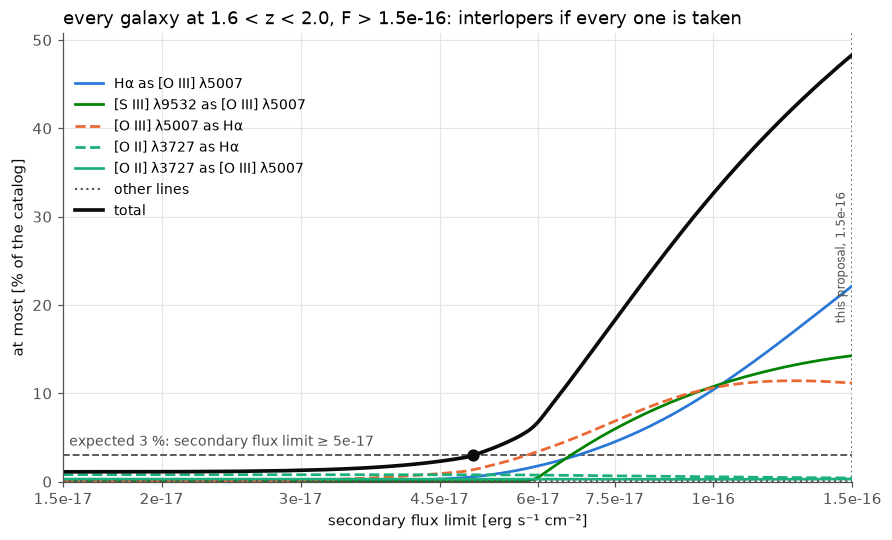

{
 "Ha": {
  "OIII_5007": 0.01127,
  "OII_3727": 0.001076
 },
 "OIII_5007": {
  "SIII_9532": 0.009805,
  "Ha": 0.007416,
  "OII_3727": 0.0004372
 }
}
━━ Interlopers by design · every galaxy at 1.6 ≤ z ≤ 2.0 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  thresholds   F > 1.50e-16 (other lines > 7.50e-17)
  sample       11,446,804 detected galaxies inside the range
  catalog      11,800,880 galaxies expected, 3.00 % of them interlopers

  line       taken for  fraction¹  potential²      P³  expected
  ─────────  ─────────  ─────────  ──────────  ──────  ────────
  OIII_5007  Ha           1.127 %     958,653  0.1387   132,996
  OII_3727   Ha           0.108 %      91,560  0.1387    12,698
  SIII_9532  OIII_5007    0.980 %     834,309  0.1387   115,708
  Ha         OIII_5007    0.742 %     630,991  0.1387    87,515
  OII_3727   OIII_5007    0.044 %      37,205  0.1387     5,159
  ¹ asked: the share of the catalog
  ² single lines where that line would be inside the range, at a secondary flu

[romanmock] catalog: scanning 67 slices with 64 worker(s) …

 done in 33 s



━━ Catalog · every galaxy · 1.6 ≤ z_assigned ≤ 2.0 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  thresholds       F > 1.50e-16 (other lines > 7.50e-17)
  line fluxes      rescaled (galacticus_like); [O III] doublet per_galaxy
  identification   by design, shares of the catalog: OIII_5007 → Ha 1.13 % (P 0.139), OII_3727 → Ha
                   0.108 % (P 0.139), SIII_9532 → OIII_5007 0.98 % (P 0.139), Ha → OIII_5007 0.742 %
                   (P 0.139), OII_3727 → OIII_5007 0.0437 % (P 0.139)
  sky area         2578.31 deg² (estimated from the sky patches of the mock)
  base catalog     100,805,121 of its 403,068,868 galaxies detected
  columns          gal_id, ra, dec, redshift_true, redshift_rsd, redshift_assigned, id_outcome,
                   line_true, line_assigned, n_det

  galaxies                                       number     share
  ─────────────────────────────────────────  ──────────  ────────
  multi-line                                 10,534,966   89.27 %
  sin


── Interlopers by design: asked and made ───────────────────────────────────────────────────────────
  line       taken for    asked     made  interlopers  expected
  ─────────  ─────────  ───────  ───────  ───────────  ────────
  OIII_5007  Ha         1.127 %  1.127 %      132,980   132,996
  OII_3727   Ha         0.108 %  0.109 %       12,814    12,698
  SIII_9532  OIII_5007  0.980 %  0.982 %      115,914   115,708
  Ha         OIII_5007  0.742 %  0.742 %       87,535    87,515
  OII_3727   OIII_5007  0.044 %  0.044 %        5,177     5,159
  11,801,224 galaxies in the catalog (11,800,880 expected); each pair's interlopers are drawn one by
  one, so their number scatters by about its square root



[romanmock] wrote to /pscratch/sd/w/willlake/RomanMocks/examples/all_z1p6_2p0_design/
            all_z1p6_2p0.hdf5, all_z1p6_2p0_summary.json, all_z1p6_2p0_proposal.npz


In [8]:
proposal_all = base.make_proposal((1.6, 2.0), line="all", flux_limit=1.5e-16, interloper_fraction=0.03, n_workers=N_WORKERS)
proposal_all.plot_secondary()
plt.show()
table_all = proposal_all.fraction_template(0.03, secondary_flux_limit=7.5e-17)
print(json.dumps(table_all, indent=1))
cat_all = proposal_all.make_catalog(fractions=table_all, secondary_flux_limit=7.5e-17, out_dir=OUT / "all_z1p6_2p0_design",
                                    n_workers=N_WORKERS)


For every galaxy at 1.6 < z < 2.0, 11.45 M detected galaxies:

* **Some interlopers are possible at every secondary limit.** Above z ≈ 2.85 [O II] is the only line in the
  bandpass, and those single lines alone could make 1.1 % of the catalog.
* **The expected 3 % is possible from 5 × 10⁻¹⁷.**
* **Shared in proportion at 7.5 × 10⁻¹⁷:** [O III] → Hα 1.13 %, [S III] λ9532 → [O III] 0.98 %, Hα → [O III]
  0.74 %, [O II] → Hα 0.11 % and [O II] → [O III] 0.04 %.
* **Made:** 3.003 % (354,420 interlopers), each pair within its scatter. The 11,446,804 galaxies with a correct redshift
  are exactly the sample: none is lost, because a single line is taken for another only where it then lands inside the
  range.

## What is in the catalogs

These are the parts of the two catalogs (notebook 01 explains `id_outcome`, `line_true` and `line_assigned`), with one
entry per kind of interloper, and their dN/dz against the assigned redshift.

(a) Hα, 0.5 % [O III] + 0.5 % [S III]: 15,012,974 galaxies
  all                       15,012,974   100.000 %


  multi_line                14,541,036    96.856 %


  single_correct               321,887     2.144 %
  galaxies                  14,862,923    99.001 %
  interlopers                  150,051     0.999 %
  SIII_9532_as_Ha               75,078     0.500 %
  OIII_5007_as_Ha               74,973     0.499 %


(b) every galaxy, 3 % in proportion: 11,801,224 galaxies
  all                       11,801,224   100.000 %


  multi_line                10,534,966    89.270 %


  single_correct               911,838     7.727 %


  galaxies                  11,446,804    96.997 %
  interlopers                  354,420     3.003 %
  OIII_5007_as_Ha              132,980     1.127 %
  SIII_9532_as_OIII_5007       115,914     0.982 %
  Ha_as_OIII_5007               87,535     0.742 %
  OII_3727_as_Ha                12,814     0.109 %
  OII_3727_as_OIII_5007          5,177     0.044 %


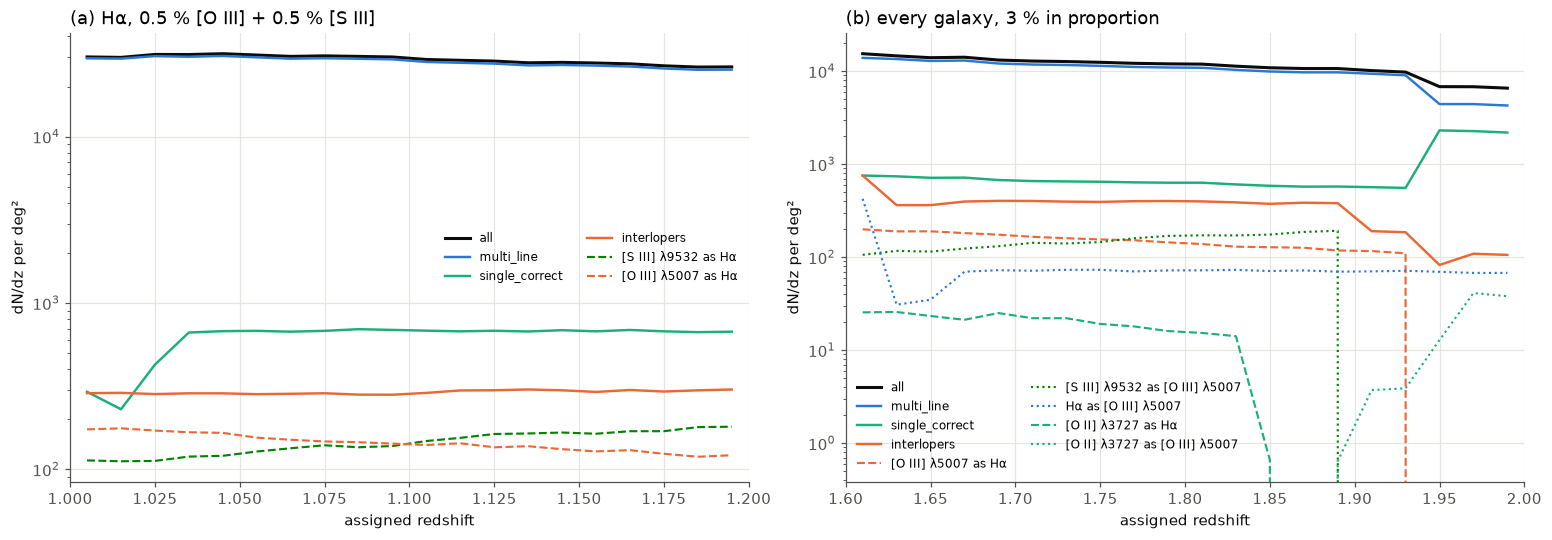

In [9]:
COLORS = {"all": TEXT_PRIMARY, "multi_line": OUTCOME_COLORS["MULTI_LINE"], "single_correct": OUTCOME_COLORS["SINGLE_CORRECT"],
          "interlopers": OUTCOME_COLORS["SINGLE_MISID"]}


def show_components(cat, name, ax, edges, min_count=100):
    """Print the components of a catalog and draw dN/dz of each against the assigned redshift. A kind of interloper
    has the colour of its true line and one line style per line it is taken for; those with fewer than min_count
    galaxies are listed only."""
    comp = cat.components()
    zc = 0.5 * (edges[1:] + edges[:-1])
    styles = {}
    print(f"{name}: {len(cat):,} galaxies")
    for which, n in comp.items():
        print(f"  {which:<24s}{n:>12,}{100 * n / comp['all']:>10.3f} %")
        if which == "galaxies" or n < min_count:
            continue
        if which in COLORS:
            ax.plot(zc, cat.subset(which).dndz(edges), color=COLORS[which], lw=2.0 if which == "all" else 1.6, label=which)
        else:
            true, taken = which.split("_as_")
            ls = styles.setdefault(taken, ("--", ":", "-.")[len(styles) % 3])
            ax.plot(zc, cat.subset(which).dndz(edges), color=feature_color(true), ls=ls, lw=1.4,
                    label=f"{feature_label(true)} as {feature_label(taken)}")
    ax.set_yscale("log")
    ax.set_xlim(edges[0], edges[-1])
    ax.set_xlabel("assigned redshift")
    ax.set_ylabel("dN/dz per deg²")
    ax.set_title(name, loc="left")
    ax.legend(fontsize=8, ncol=2)


fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), constrained_layout=True)
show_components(cat, "(a) Hα, 0.5 % [O III] + 0.5 % [S III]", axes[0], np.linspace(1.0, 1.2, 21))
show_components(cat_all, "(b) every galaxy, 3 % in proportion", axes[1], np.linspace(1.6, 2.0, 21))
plt.show()


## Summary

* **`make_proposal(..., interloper_fraction=...)`** scans the secondary limit. It shows the most each kind of
  interloper can make of the catalog at every secondary limit, and from which one the expected total is possible:
  6.1 × 10⁻¹⁷ for 1 % in the Hα catalog at 1.0–1.2, and 5 × 10⁻¹⁷ for 3 % of every galaxy at 1.6–2.0.
* **`make_catalog(fractions=..., secondary_flux_limit=...)`** makes the interlopers asked for: 0.499 % and 0.500 % for
  0.5 % each, 3.003 % for 3 %. The sample is untouched. `design` says what a table takes, and refuses one that the
  single lines cannot meet. `fraction_template` shares a total in proportion.
* The notebook ran in 3.2 minutes on a CPU node.